In [1]:
import os,sys
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_ENABLE_X64"] = "True"
from pathlib import Path

import jax.numpy as jnp

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'datapaths.py').exists():
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))
if str(ROOT.parent) not in sys.path:
    sys.path.append(str(ROOT.parent))

from datapaths import input_paths
from utils import (bf16_torch_to_jax, flatten_tokens_features, clip, binarize, reduce_list_half_preserve_extremes)
from utils_loading import collect_data


In [2]:
# Global knobs
DBG = 0
MODEL = 'deepseek'
LANGUAGE_A = 'german'
LANGUAGE_B = 'english'
AUX = 'target'
MIN_TOKEN_LENGTH = 40
MASK = 2
N_LOADED_TOKENS = MIN_TOKEN_LENGTH - MASK
N_FILES = 1 if DBG else 100
FILTER_LAYER = None

N_TOKENS = 20
NBITS = 0
AVG_TOKENS = 1

INPUT_PATH = input_paths[MODEL][LANGUAGE_A][LANGUAGE_B][AUX][str(MIN_TOKEN_LENGTH)]
print('INPUT_PATH =', INPUT_PATH)


INPUT_PATH = /home/laios/activations/opus_german_english/deepseek_german_english_target


In [3]:
all_activations = collect_data(
    input_path=INPUT_PATH,
    filter_layer=FILTER_LAYER,
    n_loaded_tokens=N_LOADED_TOKENS,
    n_files=N_FILES,
    mask=MASK,
)

Collect File: 100%|██████████| 100/100 [07:53<00:00,  4.74s/it]


In [4]:
# Same layer-selection logic as II_santiago.py: build full list, then reduce by half.
n_layers = len(list(all_activations.keys()))
rows = [f"layer_{i}" for i in range(1, n_layers)]
rows = reduce_list_half_preserve_extremes(rows)

selected_layer = rows[int(len(rows) * 3/5.)]
print('Selected layer =', selected_layer)

layer_tensor = all_activations[selected_layer]
act = bf16_torch_to_jax(layer_tensor[:, -N_TOKENS:, :])

if NBITS == 0:
    act = clip(act).astype(jnp.double)
    if AVG_TOKENS == 1:
        act = act.mean(axis=1, keepdims=True)
else:
    raise ValueError('This notebook is configured for NBITS = 0 only.')

a = flatten_tokens_features(act)
activations_en = {selected_layer: a}

print('Available reduced layers:', rows)
print('Final tensor:', selected_layer, a.shape)

Selected layer = layer_37
Available reduced layers: ['layer_1', 'layer_2', 'layer_4', 'layer_6', 'layer_8', 'layer_10', 'layer_12', 'layer_14', 'layer_16', 'layer_18', 'layer_20', 'layer_22', 'layer_24', 'layer_26', 'layer_28', 'layer_30', 'layer_33', 'layer_35', 'layer_37', 'layer_39', 'layer_41', 'layer_43', 'layer_45', 'layer_47', 'layer_49', 'layer_51', 'layer_53', 'layer_55', 'layer_57', 'layer_61']
Final tensor: layer_37 (1000, 7168)


In [5]:
E = a.shape[1]

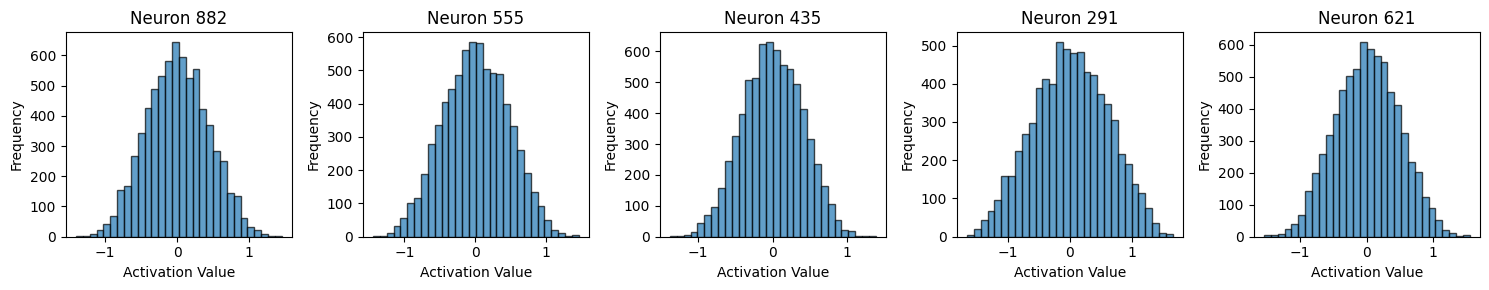

In [6]:
import numpy as np

import matplotlib.pyplot as plt

# Randomly sample a few neuron indices
n_neurons_to_plot = 5
neuron_indices = np.random.choice(a.shape[0], size=n_neurons_to_plot, replace=False)

# Create subplots for each neuron
fig, axes = plt.subplots(1, n_neurons_to_plot, figsize=(15, 3))

for idx, neuron_idx in enumerate(neuron_indices):
    axes[idx].hist(a[neuron_idx, :], bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'Neuron {neuron_idx}')
    axes[idx].set_xlabel('Activation Value')
    axes[idx].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [7]:
from binary_dimension import compute_histogram_jax, select_range
from binary_dimension.utils import initial_gauss, pairwise_hamming_scan
from binary_dimension.optimization import DKL_Optimizer
from binary_dimension.distance_models import LinearDistanceModel 

def compute_BID(r,P,a_min=0.01,a_max=0.2,max_iter=1000,error=1e-10,lr=1.2,verbose=True):

  ### Select range for fitting
  _r,_P = select_range(r, P, a_min=a_min, a_max=a_max) 
  
  ### Initialization of parameters and optimizer
  distance_model = LinearDistanceModel()
  theta_init = initial_gauss(_r,_P)
  Dkl_optimizer = DKL_Optimizer(_r,_P, distance_model)

  ### Optimization
  theta_opt , log_DKL , Nit = Dkl_optimizer.optimize(theta_init,max_iter=max_iter,error=error,lr=lr)

  ### Computing P_model with optimizer parameters
  Pmod = distance_model.P_model(_r, theta_opt)

  if verbose: 
    print(f'Optimized parameters theta: {theta_opt}')
    print(f'Log D_KL at optimum: {log_DKL}')
    print(f'Number of iterations: {Nit}') 

  return theta_opt, log_DKL, Nit, _r, _P, Pmod

r , P = compute_histogram_jax(binarize(a))

In [25]:
dis = pairwise_hamming_scan(binarize(a))
first_d = jnp.min(dis,axis=1)
first_d_mu = jnp.mean(first_d)
first_d_std = jnp.std(first_d)
print(f'{dis.shape=}')

dis.shape=(1000, 999)


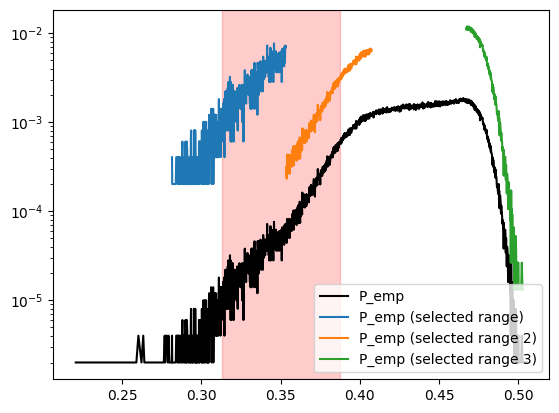

In [24]:
import matplotlib.pyplot as plt

a_min1 = 0.0001
a_max1 = 0.01

a_min2 = 0.01
a_max2 = 0.2

a_min3 = .85
a_max3 = 1

_r1,_P1 = select_range(r, P, a_min=a_min1, a_max=a_max1)
_r2,_P2 = select_range(r, P, a_min=a_min2, a_max=a_max2) 
_r3,_P3 = select_range(r, P, a_min=a_min3, a_max=a_max3)

fig, ax = plt.subplots(1)

ax.plot(r/E, P, label='P_emp',color='black')
ax.plot(_r1/E, _P1, label='P_emp (selected range)')
ax.plot(_r2/E, _P2, label='P_emp (selected range 2)')
ax.plot(_r3/E, _P3, label='P_emp (selected range 3)')


ax.legend()

ax.set_yscale('log')

n_stds = 1
ax.axvspan((first_d_mu - n_stds * first_d_std)/E, 
           (first_d_mu + n_stds * first_d_std)/E, 
           alpha=0.2, color='red', 
           label=f'±{n_stds} std')

plt.show()

Optimized parameters theta: [571.99707597   1.82034697]
Log D_KL at optimum: -3.1440632234859702
Number of iterations: 25
Optimized parameters theta: [1043.69173874    1.66734866]
Log D_KL at optimum: -5.926117578294769
Number of iterations: 21
Optimized parameters theta: [4.46171850e+03 6.72029613e-01]
Log D_KL at optimum: -6.394860805249524
Number of iterations: 18


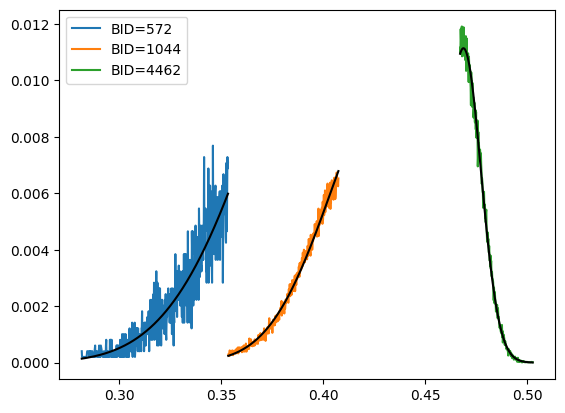

In [9]:
fig, ax = plt.subplots(1)
for enum_id, (a_min, a_max) in enumerate([(a_min1, a_max1), 
                                          (a_min2, a_max2),
                                          (a_min3, a_max3),
                                          ]):
    theta_opt, log_DKL, Nit, _r, _P, Pmod = compute_BID(r,
                                                        P,
                                                        a_min=a_min,
                                                        a_max=a_max,
                                                        verbose=True,
                                                        )

    ax.plot(_r/E, _P, label=f'BID={theta_opt[0]:.0f}')
    ax.plot(_r/E, Pmod,color='black')
    # ax.set_yscale('log')
    ax.legend()
plt.show()

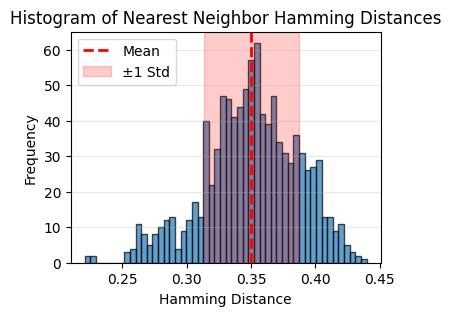

In [23]:
plt.figure(figsize=(4, 3))
plt.hist(first_d/E, bins=50, edgecolor='black', alpha=0.7)
plt.axvline(first_d_mu/E, color='red', linestyle='--', linewidth=2, label='Mean')
plt.axvspan((first_d_mu - first_d_std)/E, (first_d_mu + first_d_std)/E, alpha=0.2, color='red', label='±1 Std')
plt.xlabel('Hamming Distance')
plt.ylabel('Frequency')
plt.title('Histogram of Nearest Neighbor Hamming Distances')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

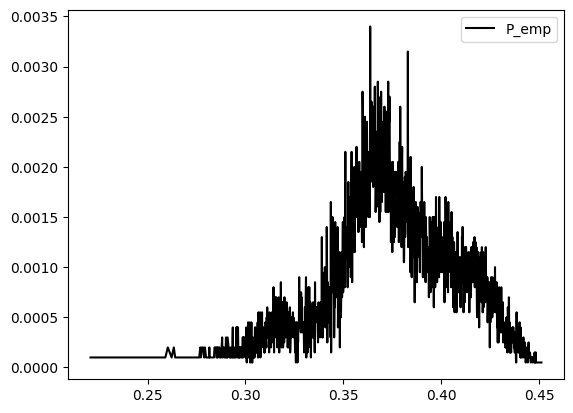

In [33]:
# Get the smallest k=10 hamming distances for each neuron
k = 20
smallest_k_distances = np.sort(dis, axis=1)[:, :k]

# Flatten to plot all smallest k distances together
smallest_k_flat = smallest_k_distances.flatten()


r , P = jnp.unique(smallest_k_flat,return_counts=True)
P /= np.sum(P)

fig, ax = plt.subplots(1)
ax.plot(r/E, P, label='P_emp',color='black')
ax.legend()

Optimized parameters theta: [1372.17600724    1.48136297]
Log D_KL at optimum: -3.4100143525617828
Number of iterations: 40


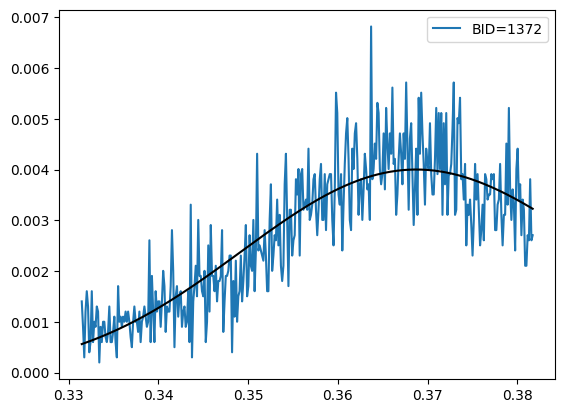

In [36]:
fig, ax = plt.subplots(1)
a_min = 0.1
a_max = 0.6
for enum_id, (a_min, a_max) in enumerate([(a_min, a_max), 
                                          ]):
    theta_opt, log_DKL, Nit, _r, _P, Pmod = compute_BID(r,
                                                        P,
                                                        a_min=a_min,
                                                        a_max=a_max,
                                                        verbose=True,
                                                        )

    ax.plot(_r/E, _P, label=f'BID={theta_opt[0]:.0f}')
    ax.plot(_r/E, Pmod,color='black')
    ax.legend()
plt.show()